# Mechanism inspection: GP

Goal: visualise how nonlinear `GPMechanism` actually is,
and understand what knobs control the degree of nonlinearity.

In [78]:
import sys
sys.path.insert(0, '..')

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

from mcd.mechanisms import (
    GPMechanism, ANMGPMechanism,
    _N_RFF, _GP_LENGTH_SCALE, build_mechanism
)

rng = np.random.default_rng(42)
x1d = np.linspace(-3, 3, 300).reshape(-1, 1)  # 1-parent sweep
s0   = np.zeros(300)                            # noise = 0  → pure mean
print('defaults: N_RFF =', _N_RFF, '  GP_LENGTH_SCALE =', _GP_LENGTH_SCALE)

defaults: N_RFF = 32   GP_LENGTH_SCALE = 2


## 1. GP mechanisms — mean function and source sensitivity

With s=0: `x = f(pa, 0)` — the pure mean function.

**GP (non-additive)**: `x = RFF([pa, s]) + c_s * s`. `s` enters the RFF nonlinearly alongside parents; `c_s` sets a monotonicity floor on source sensitivity.

**ANM-GP (additive)**: `x = RFF(pa) + s`. `s` enters purely additively, so source sensitivity is identically 1 everywhere.

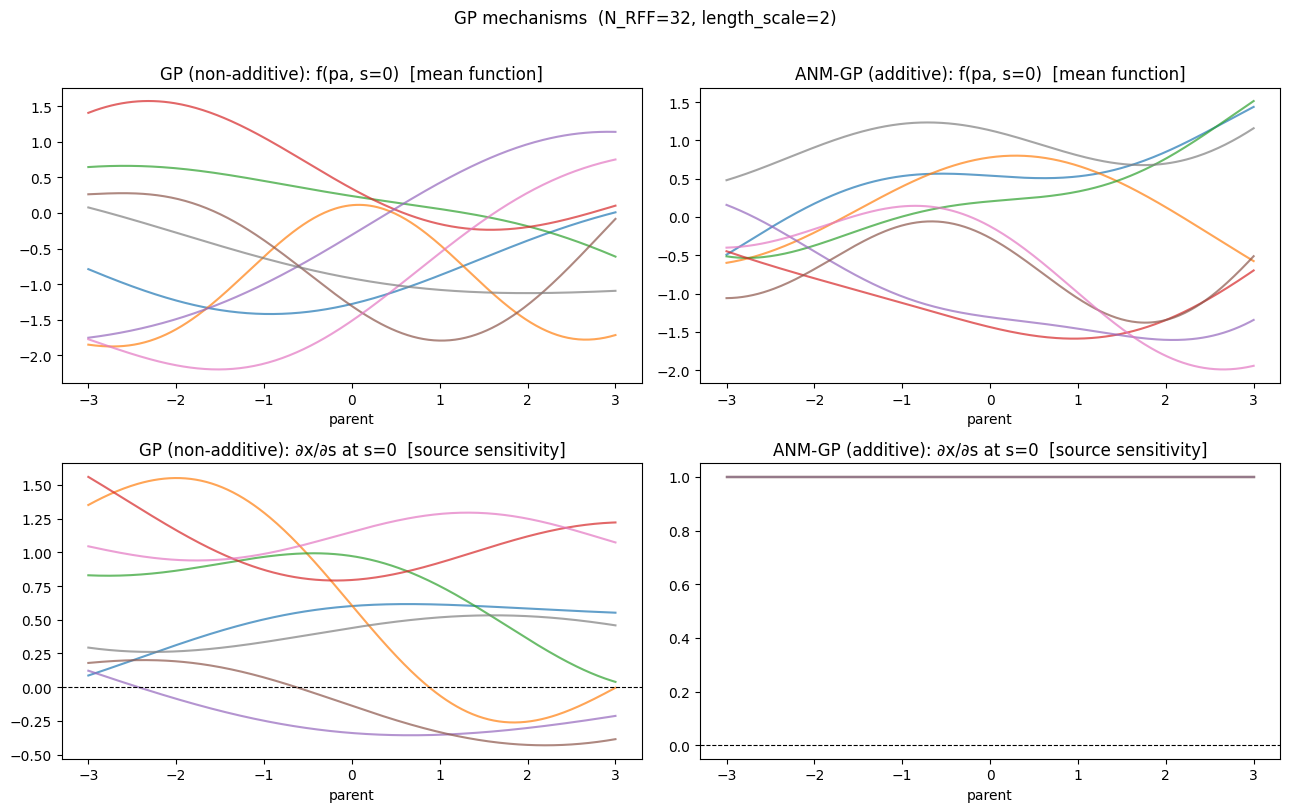

In [79]:
N_DRAWS = 8
eps_s = 1e-4
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

for col, (key, label) in enumerate([('gp', 'GP (non-additive)'), ('anm_gp', 'ANM-GP (additive)')]):
    for _ in range(N_DRAWS):
        mech = build_mechanism(key, n_parents=1, rng=rng)
        mean_fn = mech(x1d, s0)
        dsens = (mech(x1d, np.full(300, eps_s)) - mech(x1d, np.full(300, -eps_s))) / (2 * eps_s)
        axes[0, col].plot(x1d.ravel(), mean_fn, alpha=0.7)
        axes[1, col].plot(x1d.ravel(), dsens, alpha=0.7)
    axes[0, col].set_title(f'{label}: f(pa, s=0)  [mean function]')
    axes[0, col].set_xlabel('parent')
    axes[1, col].set_title(f'{label}: ∂x/∂s at s=0  [source sensitivity]')
    axes[1, col].set_xlabel('parent')
    axes[1, col].axhline(0, color='k', lw=0.8, ls='--')

fig.suptitle(f'GP mechanisms  (N_RFF={_N_RFF}, length_scale={_GP_LENGTH_SCALE})', y=1.01)
plt.tight_layout()
plt.show()

## 2. GP curvature: length scale sweep

Median curvature (|Δ²y|) across random draws as a function of length scale.
Larger length_scale → smoother mean function → less nonlinear.

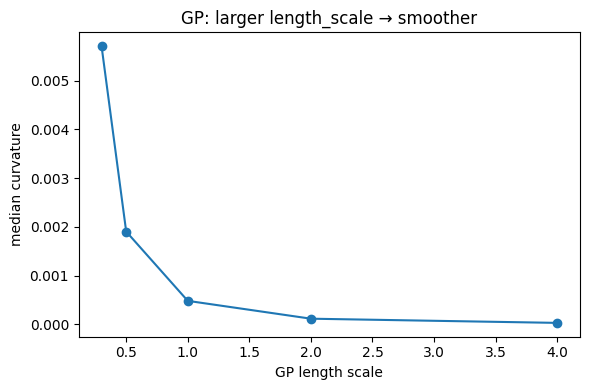

In [80]:
def mean_abs_curvature(mech, x_grid, s0):
    """Mean |second finite diff| over the grid as a nonlinearity proxy."""
    y = mech(x_grid, s0)
    d2 = np.diff(y, n=2)
    return float(np.mean(np.abs(d2)))

# --- GP length scale sweep ---
length_scales = [0.3, 0.5, 1.0, 2.0, 4.0]
N_S = 100

gp_med = []
for ls in length_scales:
    curv = []
    for _ in range(N_S):
        gp = GPMechanism(
            omega=rng.normal(0.0, 1.0 / ls, (_N_RFF, 2)),
            phase=rng.uniform(0.0, 2.0 * np.pi, _N_RFF),
            alpha=rng.normal(0.0, 1.0, _N_RFF),
            c_s=float(rng.uniform(0.3, 0.7)),
        )
        curv.append(mean_abs_curvature(gp, x1d, s0))
    gp_med.append(np.median(curv))

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(length_scales, gp_med, 'o-')
ax.set_xlabel('GP length scale')
ax.set_ylabel('median curvature')
ax.set_title('GP: larger length_scale → smoother')
plt.tight_layout()
plt.show()

## 3. 2-D parent: surface plot

Check that the 2-parent GP case looks reasonable (not degenerate).

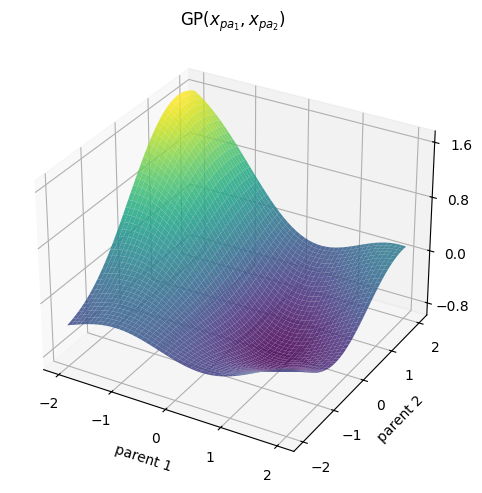

In [81]:
grid_1d = np.linspace(-2, 2, 50)
pa1, pa2 = np.meshgrid(grid_1d, grid_1d)
pa2d = np.stack([pa1.ravel(), pa2.ravel()], axis=1)  # (2500, 2)
s2d  = np.zeros(len(pa2d))

fig = plt.figure(figsize=(6, 5))
ax = fig.add_subplot(111, projection='3d')
mech = build_mechanism('gp', n_parents=2, rng=rng)
z = mech(pa2d, s2d).reshape(50, 50)
ax.plot_surface(pa1, pa2, z, cmap='viridis', alpha=0.85)

ticks = list(range(-2, 3))
ax.set_xticks(ticks)
ax.set_yticks(ticks)
ax.zaxis.set_major_locator(plt.MaxNLocator(4))

ax.set_title(r'$\operatorname{GP}(x_{pa_1}, x_{pa_2})$')
ax.set_xlabel('parent 1')
ax.set_ylabel('parent 2')
ax.set_zlabel('x')

plt.tight_layout()
plt.show()

## 3b. 1-parent surface: f(pa, s)

Both axes sweep together — parent on x, source on y — so you can see
how the GP mechanism interacts the two inputs.

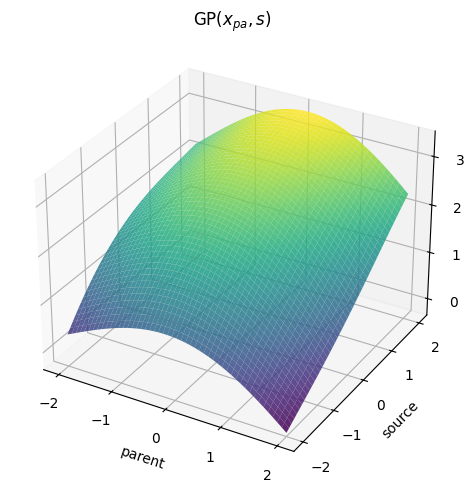

In [82]:
grid_1d_ps = np.linspace(-2, 2, 50)
pa_vals, s_vals = np.meshgrid(grid_1d_ps, grid_1d_ps)
pa_1d = pa_vals.ravel().reshape(-1, 1)   # (2500, 1)
s_1d  = s_vals.ravel()                   # (2500,)

fig = plt.figure(figsize=(6, 5))
ax = fig.add_subplot(111, projection='3d')
mech = build_mechanism('gp', n_parents=1, rng=rng)
z = mech(pa_1d, s_1d).reshape(50, 50)
ax.plot_surface(pa_vals, s_vals, z, cmap='viridis', alpha=0.85)

ticks = list(range(-2, 3))
ax.set_xticks(ticks)
ax.set_yticks(ticks)
ax.zaxis.set_major_locator(plt.MaxNLocator(4))

ax.set_title(r'$\operatorname{GP}(x_{pa}, s)$')
ax.set_xlabel('parent')
ax.set_ylabel('source')
ax.set_zlabel('x')

plt.tight_layout()
plt.show()

## 3c. Two GP draws: GP₁ and GP₂

Same setup as 3b but two independent mechanism draws shown side by side.

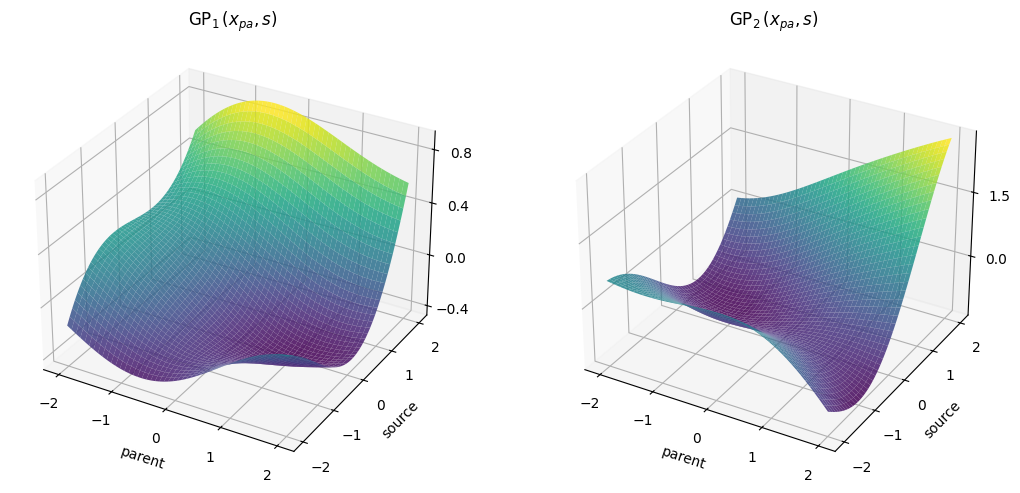

In [83]:
grid_1d_two = np.linspace(-2, 2, 50)
pa_v, s_v = np.meshgrid(grid_1d_two, grid_1d_two)
pa_in = pa_v.ravel().reshape(-1, 1)
s_in  = s_v.ravel()

fig = plt.figure(figsize=(11, 5))
ticks = list(range(-2, 3))

for col, label in enumerate([r'$\operatorname{GP}_1(x_{pa}, s)$',
                              r'$\operatorname{GP}_2(x_{pa}, s)$']):
    ax = fig.add_subplot(1, 2, col + 1, projection='3d')
    mech = build_mechanism('gp', n_parents=1, rng=rng)
    z = mech(pa_in, s_in).reshape(50, 50)
    ax.plot_surface(pa_v, s_v, z, cmap='viridis', alpha=0.85)
    ax.set_xticks(ticks)
    ax.set_yticks(ticks)
    ax.zaxis.set_major_locator(plt.MaxNLocator(4))
    ax.set_title(label)
    ax.set_xlabel('parent')
    ax.set_ylabel('source')
    # ax.set_zlabel('x')

plt.tight_layout()
plt.show()

## 4. GP: controlling nonlinearity

Two independent knobs:
- **Length scale** (larger → smoother mean function and source sensitivity)
- **`c_s`** (larger → higher floor on source sensitivity → mechanism stays more monotone in s)

Rows: different length scales. Columns: mean function and source sensitivity.

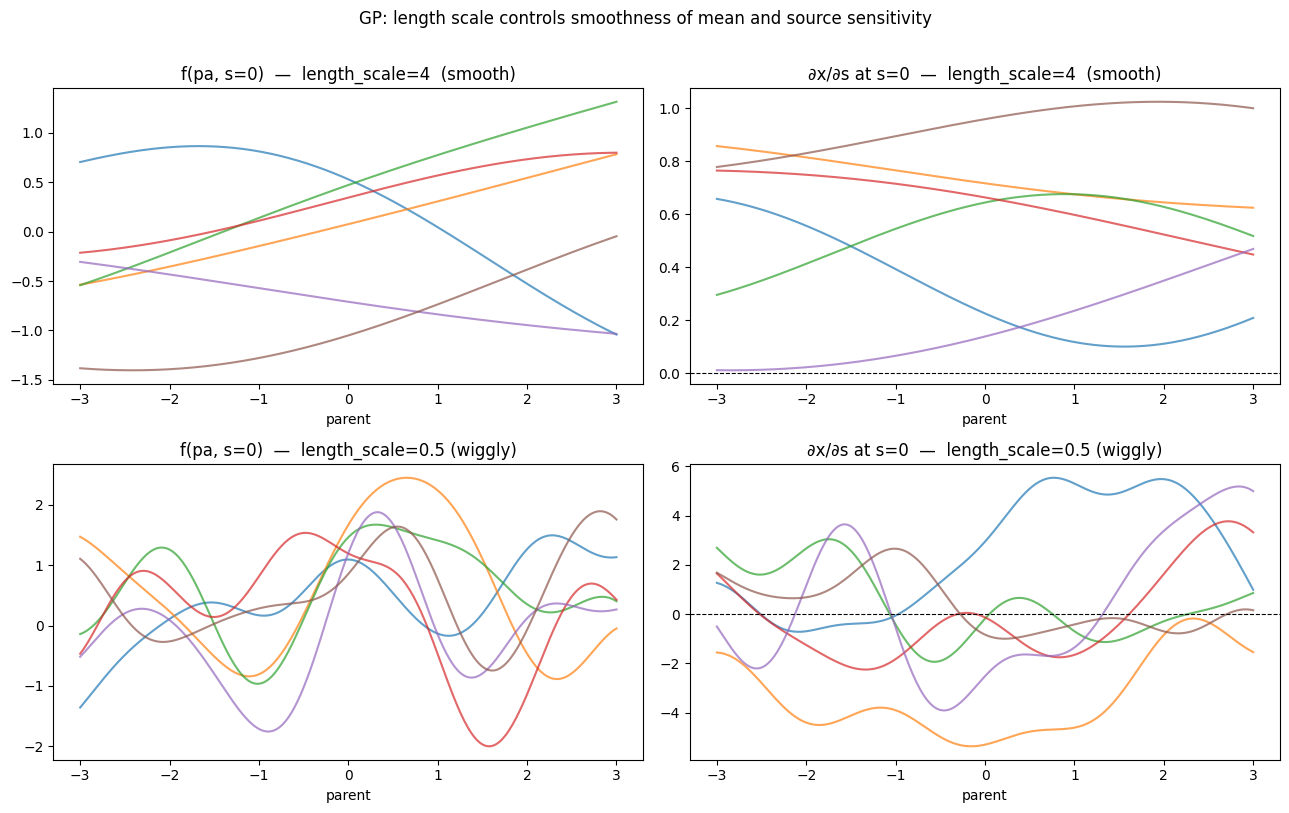

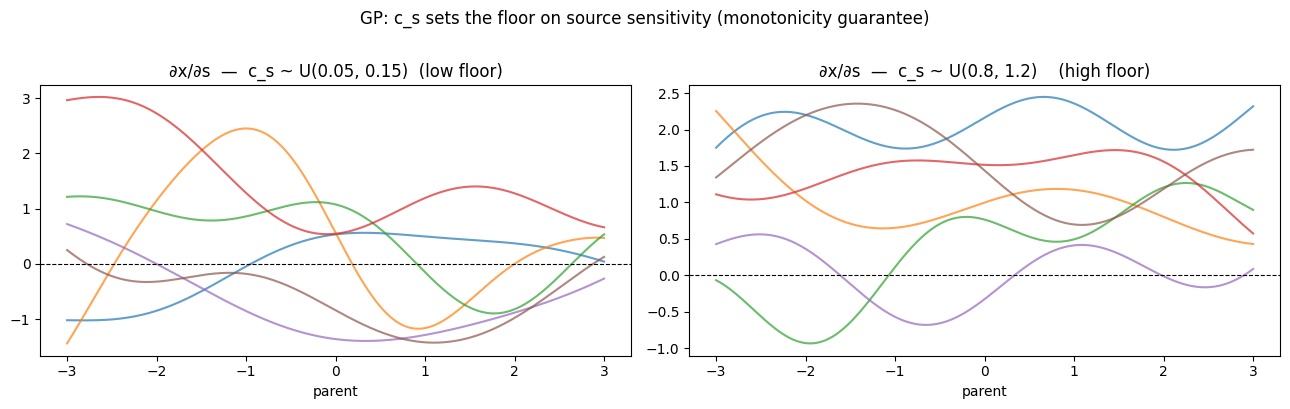

In [84]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
N_DRAWS = 6
eps_s = 1e-4

configs = [
    dict(ls=4.0, label='length_scale=4  (smooth)'),
    dict(ls=0.5, label='length_scale=0.5 (wiggly)'),
]

rng2 = np.random.default_rng(1)
for row, cfg in enumerate(configs):
    ls, label = cfg['ls'], cfg['label']
    for _ in range(N_DRAWS):
        gp = GPMechanism(
            omega=rng2.normal(0, 1/ls, (_N_RFF, 2)),
            phase=rng2.uniform(0, 2*np.pi, _N_RFF),
            alpha=rng2.normal(0, 1.0, _N_RFF),
            c_s=float(rng2.uniform(0.3, 0.7)),
        )
        mean_fn = gp(x1d, np.zeros(300))
        dsens = (gp(x1d, np.full(300, eps_s)) - gp(x1d, np.full(300, -eps_s))) / (2 * eps_s)
        axes[row, 0].plot(x1d.ravel(), mean_fn, alpha=0.7)
        axes[row, 1].plot(x1d.ravel(), dsens, alpha=0.7)
    axes[row, 0].set_title(f'f(pa, s=0)  —  {label}')
    axes[row, 0].set_xlabel('parent')
    axes[row, 1].set_title(f'∂x/∂s at s=0  —  {label}')
    axes[row, 1].set_xlabel('parent')
    axes[row, 1].axhline(0, color='k', lw=0.8, ls='--')

fig.suptitle('GP: length scale controls smoothness of mean and source sensitivity', y=1.01)
fig.tight_layout()

# Second figure: c_s floor effect on source sensitivity
fig2, axes2 = plt.subplots(1, 2, figsize=(13, 4))
rng_cs = np.random.default_rng(42)
for ax, (c_lo, c_hi, c_label) in zip(axes2, [
    (0.05, 0.15, 'c_s ~ U(0.05, 0.15)  (low floor)'),
    (0.8,  1.2,  'c_s ~ U(0.8, 1.2)    (high floor)'),
]):
    for _ in range(N_DRAWS):
        gp = GPMechanism(
            omega=rng_cs.normal(0, 1.0, (_N_RFF, 2)),
            phase=rng_cs.uniform(0, 2*np.pi, _N_RFF),
            alpha=rng_cs.normal(0, 1.0, _N_RFF),
            c_s=float(rng_cs.uniform(c_lo, c_hi)),
        )
        dsens = (gp(x1d, np.full(300, eps_s)) - gp(x1d, np.full(300, -eps_s))) / (2 * eps_s)
        ax.plot(x1d.ravel(), dsens, alpha=0.7)
    ax.axhline(0, color='k', lw=0.8, ls='--')
    ax.set_title(f'∂x/∂s  —  {c_label}')
    ax.set_xlabel('parent')

fig2.suptitle('GP: c_s sets the floor on source sensitivity (monotonicity guarantee)', y=1.01)
fig2.tight_layout()
plt.show()

## 5. Paper plots: GP with one parent and one source

Default length scale. Left: fix s=0, sweep parent. Right: fix parent=0, sweep source.

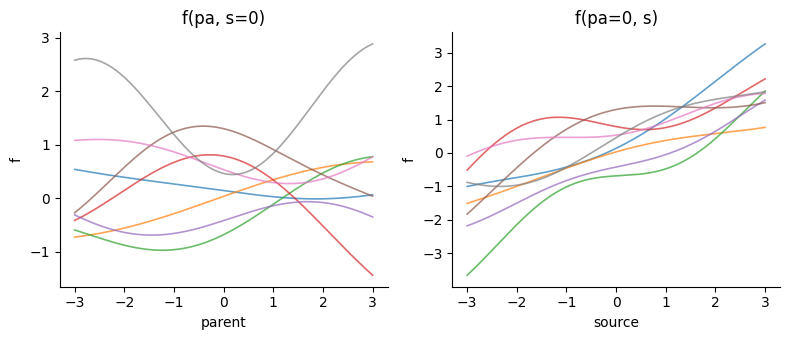

In [85]:
rng_paper = np.random.default_rng(7)
N_DRAWS   = 8
t         = np.linspace(-3, 3, 300)

fig, axes = plt.subplots(1, 2, figsize=(8, 3.5))

for _ in range(N_DRAWS):
    mech = build_mechanism('gp', n_parents=1, rng=rng_paper)

    # plot 1: vary parent, fix source = 0
    y1 = mech(t.reshape(-1, 1), np.zeros(300))
    axes[0].plot(t, y1, alpha=0.7, lw=1.2)

    # plot 2: fix parent = 0, vary source
    y2 = mech(np.zeros((300, 1)), t)
    axes[1].plot(t, y2, alpha=0.7, lw=1.2)

axes[0].set_xlabel('parent')
axes[0].set_ylabel('f')
axes[0].set_title('f(pa, s=0)')

axes[1].set_xlabel('source')
axes[1].set_ylabel('f')
axes[1].set_title('f(pa=0, s)')

for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)

fig.tight_layout()
plt.show()

---

## RandomNN mechanism

A random invertible neural network: `x = LayerNorm(MLP([pa, s]))[0]`.

Each layer is a **square** linear map (dim = n_parents + 1) followed by an invertible nonlinearity — either `tanh` (saturating) or `leaky_relu` with α ≈ 0.2 (piecewise-linear).  LayerNorm on the final hidden state keeps the output scale bounded regardless of depth or weight magnitude.

Knobs explored below:
- **depth** — number of layers; deeper → more complex mapping
- **weight_std** — scale of random weight matrices; larger → more expressive / chaotic
- **residual** — add skip connections (h + z) between layers
- **nonlinearity** — tanh vs leaky_relu character

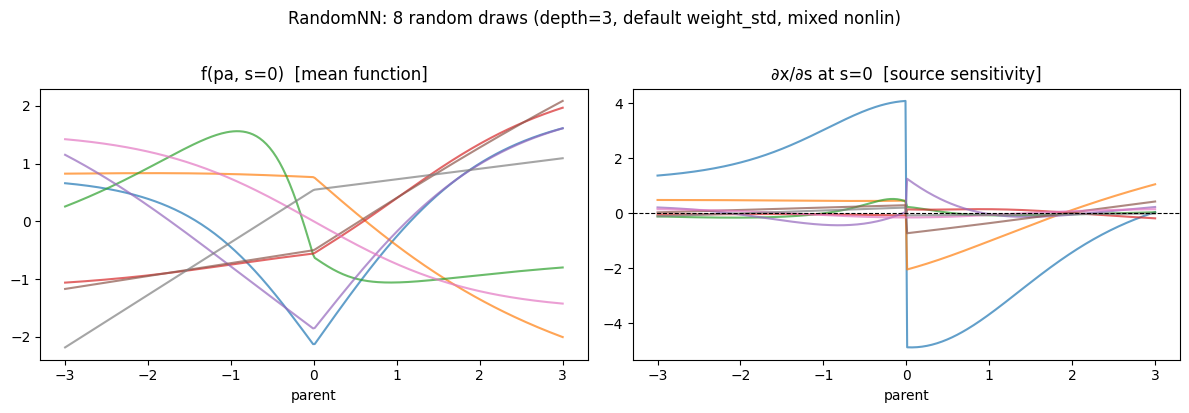

In [86]:
from mcd.mechanisms import RandomNNMechanism

def make_rnn(n_parents, depth=3, weight_std=None, residual=False, nonlin=None, rng=None):
    """Convenience factory for RandomNNMechanism with explicit knobs."""
    if rng is None:
        rng = np.random.default_rng(42)
    dim = n_parents + 1
    if weight_std is None:
        weight_std = 1.0 / np.sqrt(dim)
    nonlins = [nonlin if nonlin else str(rng.choice(['tanh', 'leaky_relu'])) for _ in range(depth)]
    weights = [rng.normal(0.0, weight_std, (dim, dim)) for _ in range(depth)]
    return RandomNNMechanism(weights=weights, nonlinearities=nonlins, residual=residual)

# Shared grid and zero-noise baseline (reuse x1d / s0 from above)
N_DRAWS = 8
eps_s = 1e-4

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
rng_nn = np.random.default_rng(42)

for _ in range(N_DRAWS):
    mech = make_rnn(n_parents=1, depth=3, rng=rng_nn)
    mean_fn = mech(x1d, s0)
    dsens = (mech(x1d, np.full(300, eps_s)) - mech(x1d, np.full(300, -eps_s))) / (2 * eps_s)
    axes[0].plot(x1d.ravel(), mean_fn, alpha=0.7)
    axes[1].plot(x1d.ravel(), dsens, alpha=0.7)

axes[0].set_title('f(pa, s=0)  [mean function]')
axes[0].set_xlabel('parent')
axes[1].set_title('∂x/∂s at s=0  [source sensitivity]')
axes[1].set_xlabel('parent')
axes[1].axhline(0, color='k', lw=0.8, ls='--')
fig.suptitle('RandomNN: 8 random draws (depth=3, default weight_std, mixed nonlin)', y=1.02)
plt.tight_layout()
plt.show()

### 3D surfaces: RandomNN

Equivalent to sections 3 / 3b / 3c for the GP mechanism.

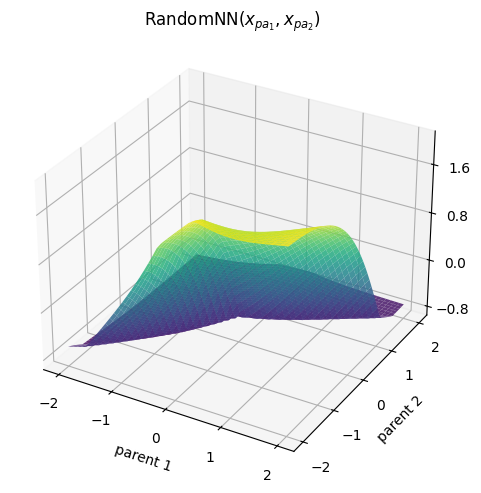

In [87]:
# 2-parent surface: f(pa1, pa2) at s=0
grid_1d = np.linspace(-2, 2, 50)
pa1, pa2 = np.meshgrid(grid_1d, grid_1d)
pa2d = np.stack([pa1.ravel(), pa2.ravel()], axis=1)  # (2500, 2)
s2d  = np.zeros(len(pa2d))

fig = plt.figure(figsize=(6, 5))
ax = fig.add_subplot(111, projection='3d')
mech = make_rnn(n_parents=2, depth=3, rng=np.random.default_rng(42))
z = mech(pa2d, s2d).reshape(50, 50)
ax.plot_surface(pa1, pa2, z, cmap='viridis', alpha=0.85)

ticks = list(range(-2, 3))
ax.set_xticks(ticks); ax.set_yticks(ticks)
ax.zaxis.set_major_locator(plt.MaxNLocator(4))
ax.set_title(r'$\operatorname{RandomNN}(x_{pa_1}, x_{pa_2})$')
ax.set_xlabel('parent 1'); ax.set_ylabel('parent 2'); ax.set_zlabel('x')
plt.tight_layout()
plt.show()

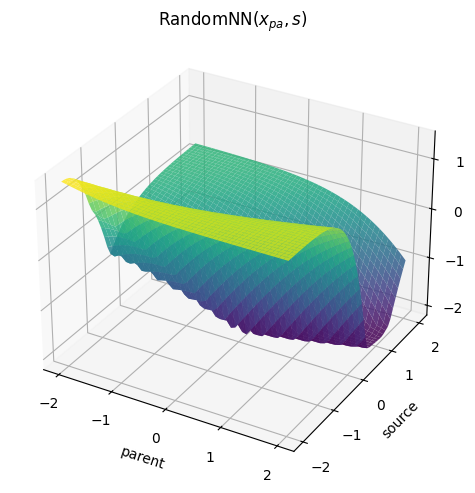

In [88]:
# 1-parent surface: f(pa, s) — both axes swept together
grid_1d_ps = np.linspace(-2, 2, 50)
pa_vals, s_vals = np.meshgrid(grid_1d_ps, grid_1d_ps)
pa_1d = pa_vals.ravel().reshape(-1, 1)
s_1d  = s_vals.ravel()

fig = plt.figure(figsize=(6, 5))
ax = fig.add_subplot(111, projection='3d')
mech = make_rnn(n_parents=1, depth=3, rng=np.random.default_rng(42))
z = mech(pa_1d, s_1d).reshape(50, 50)
ax.plot_surface(pa_vals, s_vals, z, cmap='viridis', alpha=0.85)

ticks = list(range(-2, 3))
ax.set_xticks(ticks); ax.set_yticks(ticks)
ax.zaxis.set_major_locator(plt.MaxNLocator(4))
ax.set_title(r'$\operatorname{RandomNN}(x_{pa}, s)$')
ax.set_xlabel('parent'); ax.set_ylabel('source'); ax.set_zlabel('x')
plt.tight_layout()
plt.show()

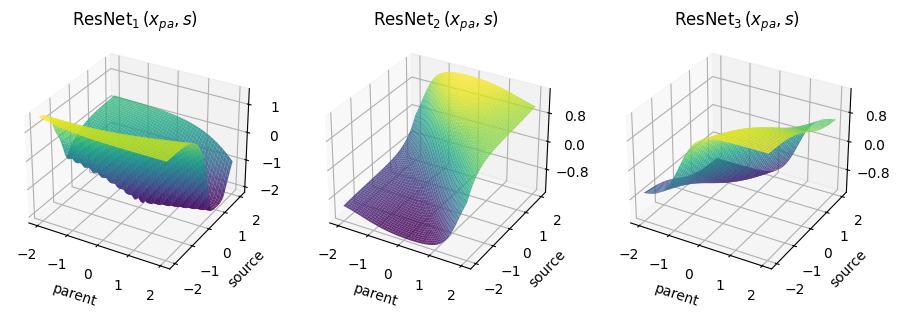

In [89]:
# Two independent draws side by side
grid_1d_two = np.linspace(-2, 2, 50)
pa_v, s_v = np.meshgrid(grid_1d_two, grid_1d_two)
pa_in = pa_v.ravel().reshape(-1, 1)
s_in  = s_v.ravel()

fig = plt.figure(figsize=(11, 5))
ticks = list(range(-2, 3))
seeds = [42, 54, 6]  
rngs = [np.random.default_rng(seed) for seed in seeds] # 6, 12,  49, 54


for col in range(len(rngs)):
    label = r'$\operatorname{ResNet}_' + str(col + 1) + r'(x_{pa}, s)$'
    ax = fig.add_subplot(1, len(rngs), col + 1, projection='3d')
    mech = make_rnn(n_parents=1, depth=3, rng=rngs[col])
    z = mech(pa_in, s_in).reshape(50, 50)
    ax.plot_surface(pa_v, s_v, z, cmap='viridis', alpha=0.85)
    ax.set_xticks(ticks); ax.set_yticks(ticks)
    ax.zaxis.set_major_locator(plt.MaxNLocator(4))
    ax.set_title(label)
    ax.set_xlabel('parent'); ax.set_ylabel('source')

# plt.tight_layout()
fig.savefig("/nfs/scistore19/locatgrp/fmontagn/mcd/outputs/resnet_source.pdf", bbox_inches='tight')
plt.show()

### Knob 1: depth

Deeper networks compose more invertible transforms → richer, more oscillatory mappings.

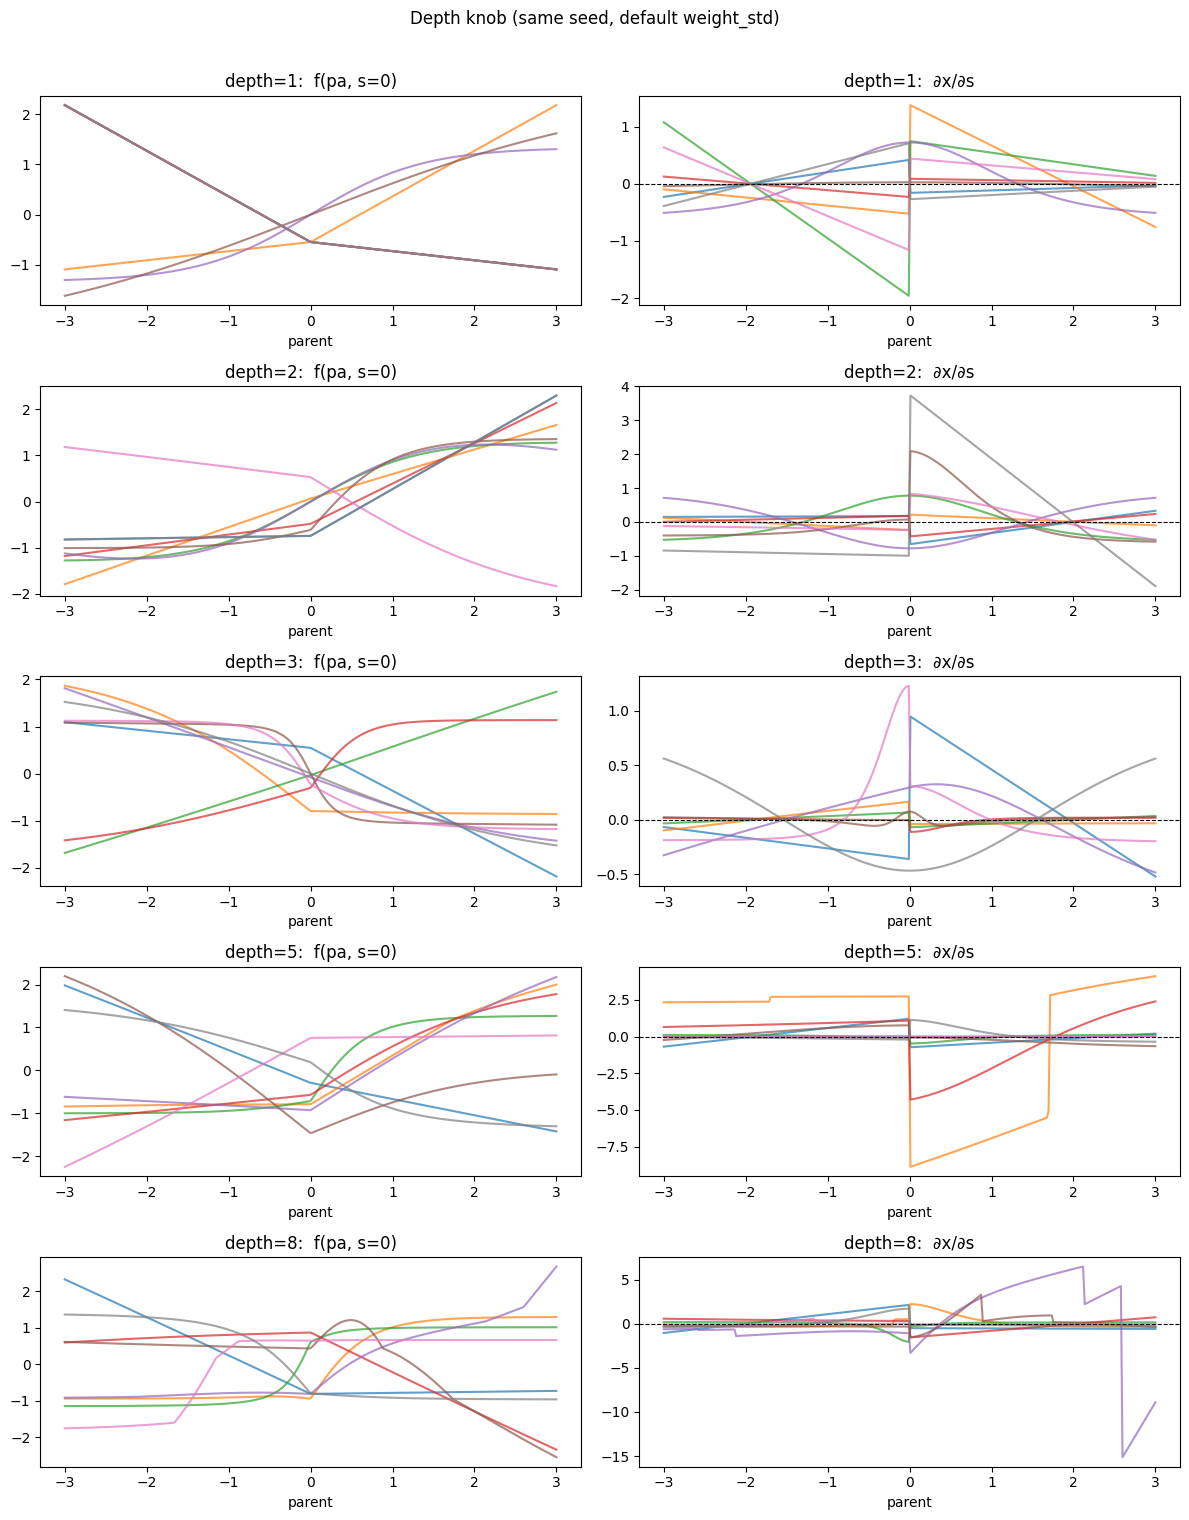

In [90]:
depths = [1, 2, 3, 5, 8]
fig, axes = plt.subplots(len(depths), 2, figsize=(12, 3 * len(depths)))

for row, depth in enumerate(depths):
    rng_d = np.random.default_rng(0)
    for _ in range(N_DRAWS):
        mech = make_rnn(n_parents=1, depth=depth, rng=rng_d)
        mean_fn = mech(x1d, s0)
        dsens = (mech(x1d, np.full(300, eps_s)) - mech(x1d, np.full(300, -eps_s))) / (2 * eps_s)
        axes[row, 0].plot(x1d.ravel(), mean_fn, alpha=0.7)
        axes[row, 1].plot(x1d.ravel(), dsens, alpha=0.7)
    axes[row, 0].set_title(f'depth={depth}:  f(pa, s=0)')
    axes[row, 0].set_xlabel('parent')
    axes[row, 1].set_title(f'depth={depth}:  ∂x/∂s')
    axes[row, 1].set_xlabel('parent')
    axes[row, 1].axhline(0, color='k', lw=0.8, ls='--')

fig.suptitle('Depth knob (same seed, default weight_std)', y=1.01)
plt.tight_layout()
plt.show()

### Knob 2: weight_std

The default scale is `1/√dim` (Xavier-style). Going above that pushes the pre-activation into saturation for tanh layers, or amplifies the slope for leaky_relu. LayerNorm at the output keeps the final range ≈ [−1, 1] regardless.

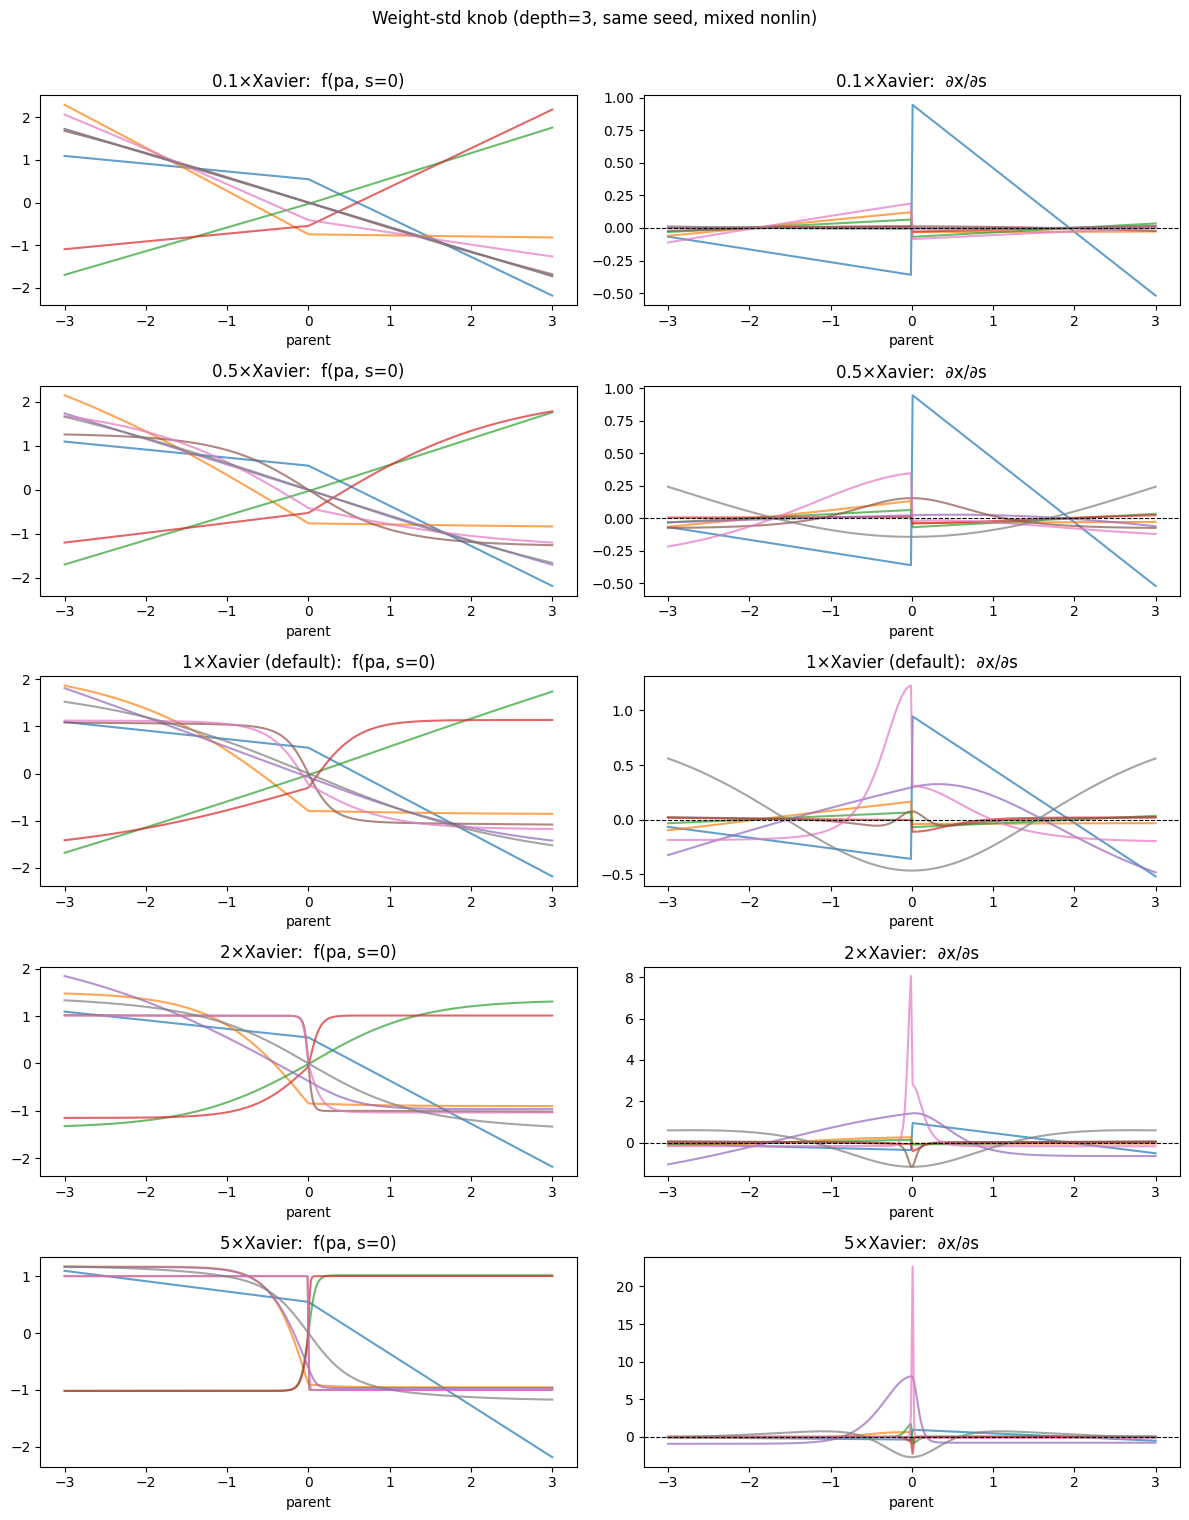

In [91]:
import numpy as np
dim_1p = 2  # n_parents=1 → dim=2
xavier = 1.0 / np.sqrt(dim_1p)
weight_stds = [0.1 * xavier, 0.5 * xavier, xavier, 2 * xavier, 5 * xavier]
labels = ['0.1×Xavier', '0.5×Xavier', '1×Xavier (default)', '2×Xavier', '5×Xavier']

fig, axes = plt.subplots(len(weight_stds), 2, figsize=(12, 3 * len(weight_stds)))

for row, (ws, lbl) in enumerate(zip(weight_stds, labels)):
    rng_ws = np.random.default_rng(0)
    for _ in range(N_DRAWS):
        mech = make_rnn(n_parents=1, depth=3, weight_std=ws, rng=rng_ws)
        mean_fn = mech(x1d, s0)
        dsens = (mech(x1d, np.full(300, eps_s)) - mech(x1d, np.full(300, -eps_s))) / (2 * eps_s)
        axes[row, 0].plot(x1d.ravel(), mean_fn, alpha=0.7)
        axes[row, 1].plot(x1d.ravel(), dsens, alpha=0.7)
    axes[row, 0].set_title(f'{lbl}:  f(pa, s=0)')
    axes[row, 0].set_xlabel('parent')
    axes[row, 1].set_title(f'{lbl}:  ∂x/∂s')
    axes[row, 1].set_xlabel('parent')
    axes[row, 1].axhline(0, color='k', lw=0.8, ls='--')

fig.suptitle('Weight-std knob (depth=3, same seed, mixed nonlin)', y=1.01)
plt.tight_layout()
plt.show()

### Knob 3: residual connections

With `residual=True` each layer computes `h = nonlin(z W) + z`.  This is analogous to ResNet skip connections: the identity shortcut carries information across layers and tends to keep gradients (and source sensitivity) more stable as depth grows.

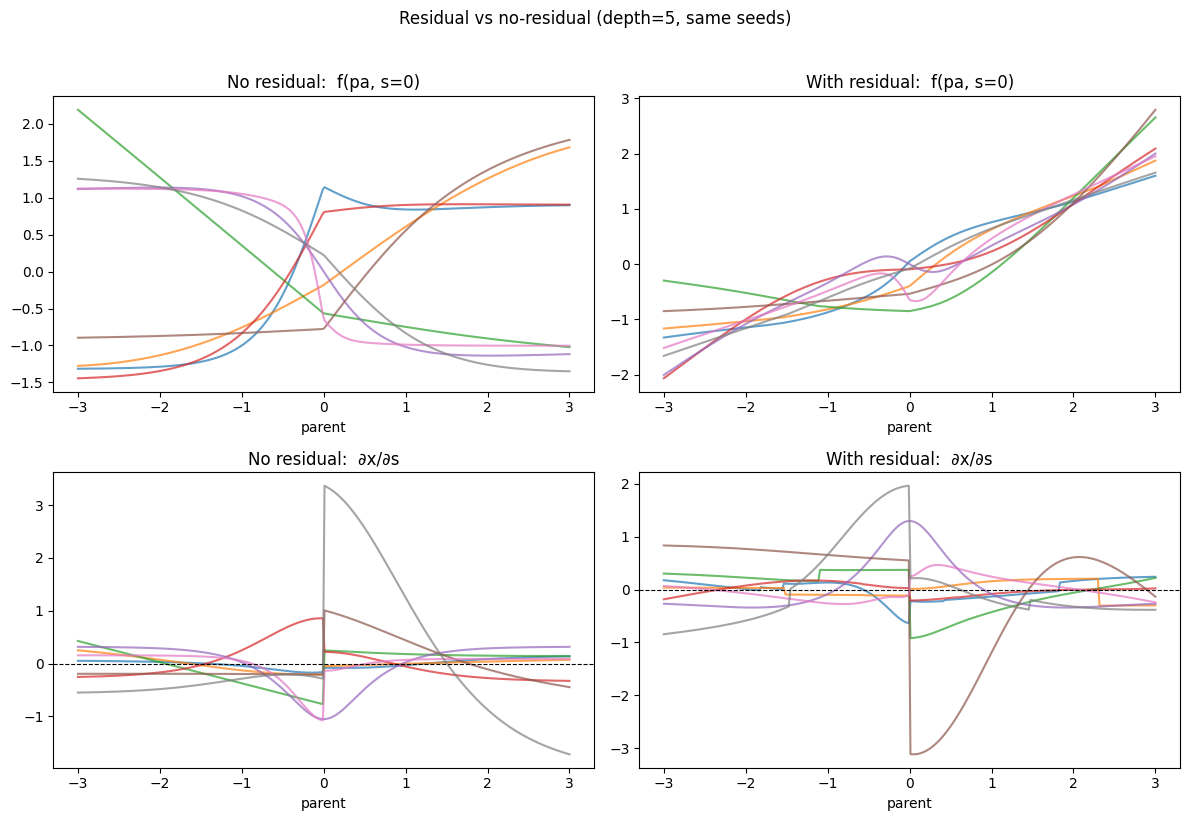

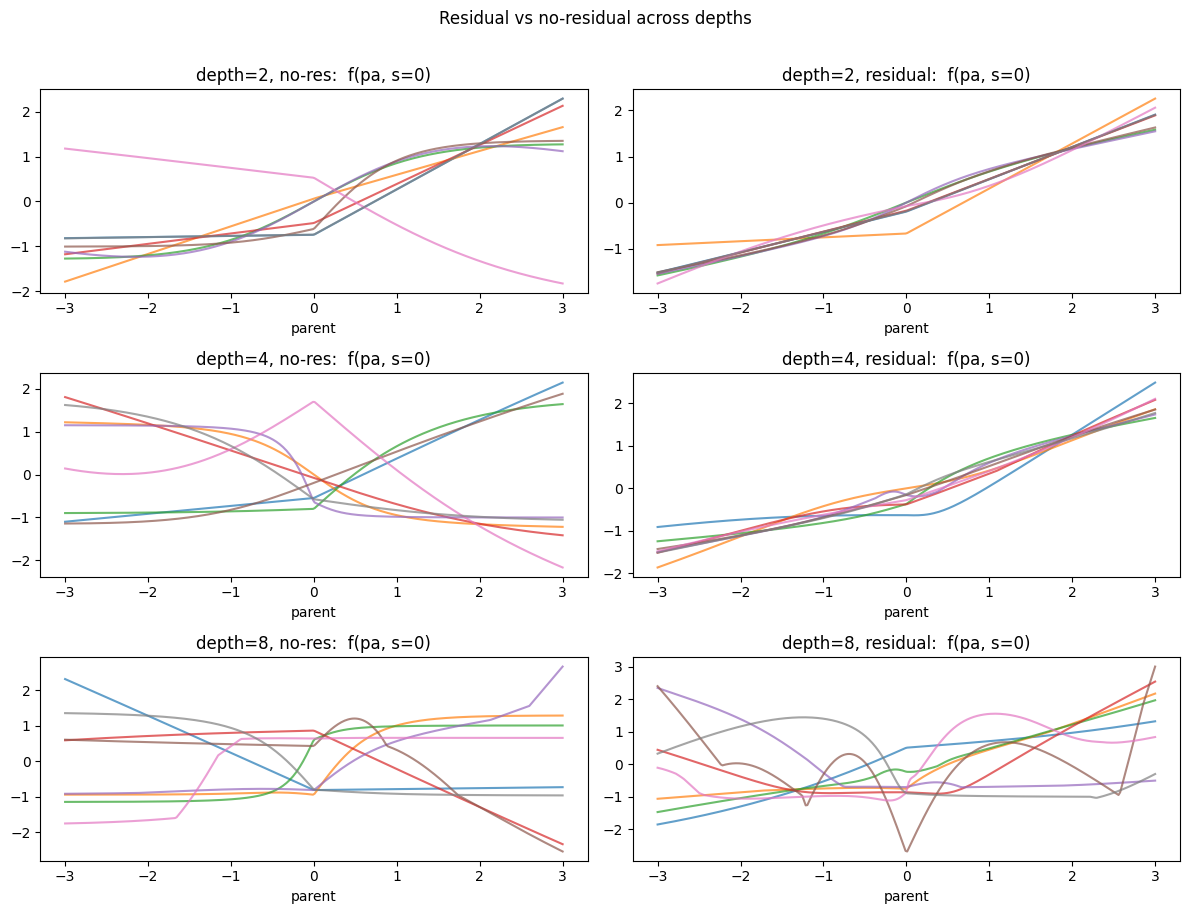

In [92]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for col, (residual, label) in enumerate([(False, 'No residual'), (True, 'With residual')]):
    rng_res = np.random.default_rng(42)
    for _ in range(N_DRAWS):
        mech = make_rnn(n_parents=1, depth=5, residual=residual, rng=rng_res)
        mean_fn = mech(x1d, s0)
        dsens = (mech(x1d, np.full(300, eps_s)) - mech(x1d, np.full(300, -eps_s))) / (2 * eps_s)
        axes[0, col].plot(x1d.ravel(), mean_fn, alpha=0.7)
        axes[1, col].plot(x1d.ravel(), dsens, alpha=0.7)
    axes[0, col].set_title(f'{label}:  f(pa, s=0)')
    axes[0, col].set_xlabel('parent')
    axes[1, col].set_title(f'{label}:  ∂x/∂s')
    axes[1, col].set_xlabel('parent')
    axes[1, col].axhline(0, color='k', lw=0.8, ls='--')

fig.suptitle('Residual vs no-residual (depth=5, same seeds)', y=1.02)
plt.tight_layout()
plt.show()

# -- same comparison but sweeping depth side by side --
depths_res = [2, 4, 8]
fig2, axes2 = plt.subplots(len(depths_res), 2, figsize=(12, 3 * len(depths_res)))

for row, depth in enumerate(depths_res):
    for col, (residual, label) in enumerate([(False, 'no-res'), (True, 'residual')]):
        rng_dr = np.random.default_rng(0)
        for _ in range(N_DRAWS):
            mech = make_rnn(n_parents=1, depth=depth, residual=residual, rng=rng_dr)
            mean_fn = mech(x1d, s0)
            axes2[row, col].plot(x1d.ravel(), mean_fn, alpha=0.7)
        axes2[row, col].set_title(f'depth={depth}, {label}:  f(pa, s=0)')
        axes2[row, col].set_xlabel('parent')

fig2.suptitle('Residual vs no-residual across depths', y=1.01)
plt.tight_layout()
plt.show()

### Knob 4: nonlinearity — tanh vs leaky_relu

`tanh` saturates and keeps outputs bounded at each layer; it produces smooth, bounded curves. `leaky_relu` (α=0.2) is piecewise-linear and does not saturate, so with large weights it can produce sharper kinks.

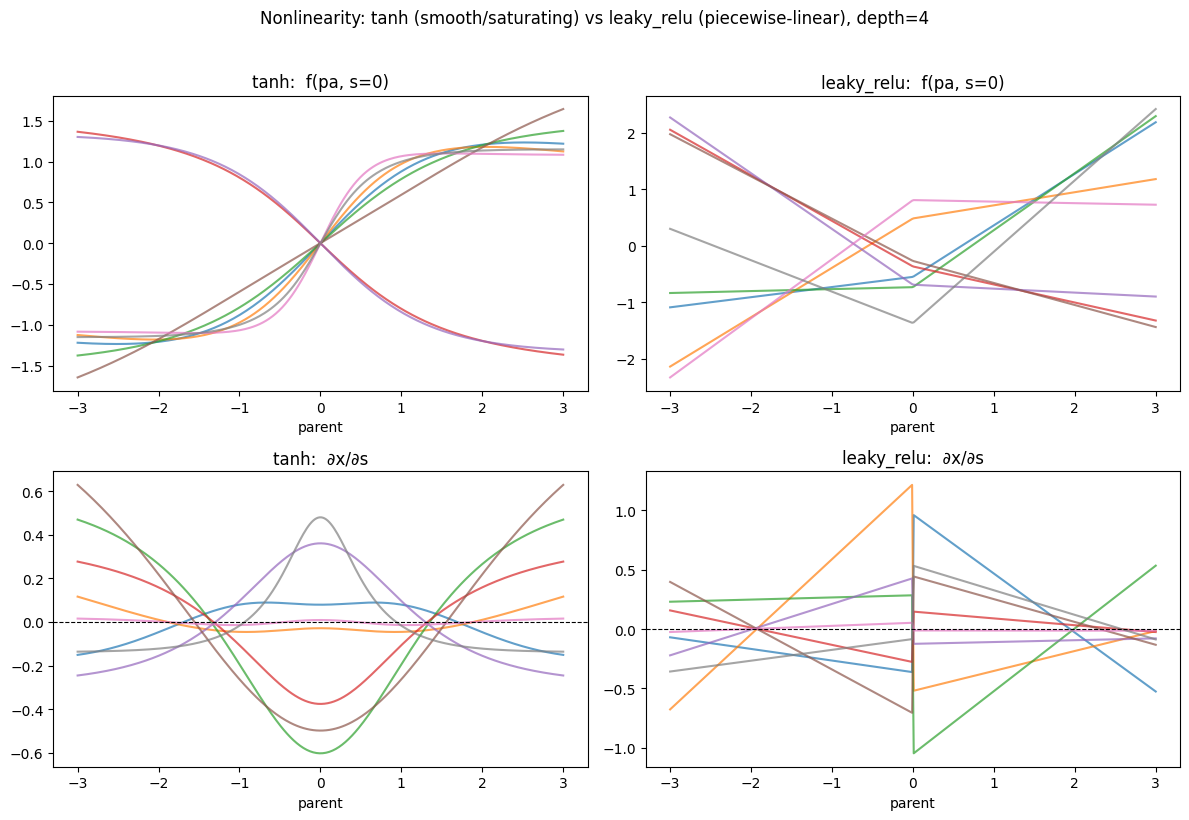

In [93]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for col, nl in enumerate(['tanh', 'leaky_relu']):
    rng_nl = np.random.default_rng(42)
    for _ in range(N_DRAWS):
        mech = make_rnn(n_parents=1, depth=4, nonlin=nl, rng=rng_nl)
        mean_fn = mech(x1d, s0)
        dsens = (mech(x1d, np.full(300, eps_s)) - mech(x1d, np.full(300, -eps_s))) / (2 * eps_s)
        axes[0, col].plot(x1d.ravel(), mean_fn, alpha=0.7)
        axes[1, col].plot(x1d.ravel(), dsens, alpha=0.7)
    axes[0, col].set_title(f'{nl}:  f(pa, s=0)')
    axes[0, col].set_xlabel('parent')
    axes[1, col].set_title(f'{nl}:  ∂x/∂s')
    axes[1, col].set_xlabel('parent')
    axes[1, col].axhline(0, color='k', lw=0.8, ls='--')

fig.suptitle('Nonlinearity: tanh (smooth/saturating) vs leaky_relu (piecewise-linear), depth=4', y=1.02)
plt.tight_layout()
plt.show()